# ETT: 直前OTを基準としたLSTM・TCN予測

直前のオイル温度（OT）を基準に、過去24時間のOT・暦情報・負荷から次の観測時刻のOT変化を予測する。LSTMとTCNを、それぞれ負荷あり・なしで比較する。

- ETThは1時間先、ETTmは15分先を予測する。
- 予測時刻のOTや負荷は使わず、直前時刻までに観測済みの情報のみを入力する。季節・時間帯は日時から周期特徴量に変換する。
- 時系列順に70%を学習、次の10%を検証、残り20%をテストに使用する。
- 標準化と月別・時刻別パターンは学習期間のみで推定する。検証・テストの入力には、予測時点で既知の分割前の履歴を含める。
- 1回の分割での比較は探索的であり、季節による偏りや汎化性能を確定するものではない。

## Colabでの準備

最初のコードセルで `keras-tcn` をインストールし、Google Driveをマウントする。EDAと同じ `/content/drive/Othercomputers/マイ Mac/assignment-main/data` から対象CSVを読み込む。上から順に実行し、必要に応じて `DATASET` を変更する。

In [140]:
%pip install -q keras-tcn

In [141]:
from pathlib import Path
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from google.colab import drive
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import StandardScaler

DATASET = "ETTh1"  # ETTh1, ETTh2, ETTm1, ETTm2
DATA_DIR = Path("/content/drive/Othercomputers/マイ Mac/assignment-main/data")
DATA_PATH = DATA_DIR / f"{DATASET}.csv"
SEED = 42
EPOCHS = 30
BATCH_SIZE = 128
PATIENCE = 5

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

drive.mount("/content/drive")

if not DATA_PATH.is_file():
    raise FileNotFoundError(
        f"CSVが見つかりません: {DATA_PATH}\n"
        "Google Driveのマウント状態とフォルダー名を確認してください。"
    )

print(f"TensorFlow: {tf.__version__}, dataset: {DATA_PATH}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
TensorFlow: 2.21.0, dataset: /content/drive/Othercomputers/マイ Mac/assignment-main/data/ETTh1.csv


## データの検証と特徴量

入力は過去24時間分とし、OT・負荷・暦情報を同じ履歴長で揃える。OTと負荷は学習期間の平均・標準偏差で標準化し、時刻・曜日・年周期はsin/cosで表現する。欠損、重複、時刻の欠落があれば学習を中止する。

In [142]:
if DATASET not in {"ETTh1", "ETTh2", "ETTm1", "ETTm2"}:
    raise ValueError("DATASETはETTh1、ETTh2、ETTm1、ETTm2のいずれかを指定してください。")

load_columns = ["HUFL", "HULL", "LUFL", "LULL"]
sensor_columns = ["OT"] + load_columns
df = pd.read_csv(DATA_PATH, parse_dates=["date"])
missing_columns = set(["date"] + sensor_columns) - set(df.columns)
if missing_columns:
    raise ValueError(f"必要な列がありません: {missing_columns}")
if df[["date"] + sensor_columns].isna().any().any():
    raise ValueError("日時またはセンサ値に欠損があります。")
if not np.isfinite(df[sensor_columns].to_numpy(dtype=float)).all():
    raise ValueError("センサ値に無限大または数値以外の値があります。")

interval = pd.Timedelta(hours=1) if DATASET.startswith("ETTh") else pd.Timedelta(minutes=15)
if not df["date"].diff().iloc[1:].eq(interval).all():
    raise ValueError(f"日時が重複、不整列、または{interval}間隔でない箇所があります。")

lookback = int(pd.Timedelta(days=1) / interval)
timestamps = df["date"]
ot_values = df["OT"].to_numpy(dtype=np.float32)
train_end = int(len(df) * 0.7)
validation_end = int(len(df) * 0.8)
if train_end <= lookback or validation_end <= train_end or validation_end >= len(df):
    raise ValueError("指定した履歴長と分割に対してデータが不足しています。")
folds = [{
    "fold": 1,
    "train_end": train_end,
    "validation_end": validation_end,
    "test_end": len(df),
}]

print("使用する負荷:", load_columns)
print(f"間隔: {interval}, 履歴: {lookback}ステップ")
for label, start, end in [("train", 0, train_end), ("validation", train_end, validation_end), ("test", validation_end, len(df))]:
    print(f"{label}: {end - start:,}件, {timestamps.iloc[start]} 〜 {timestamps.iloc[end - 1]}")

使用する負荷: ['HUFL', 'HULL', 'LUFL', 'LULL']
間隔: 0 days 01:00:00, 履歴: 24ステップ
train: 12,194件, 2016-07-01 00:00:00 〜 2017-11-21 01:00:00
validation: 1,742件, 2017-11-21 02:00:00 〜 2018-02-01 15:00:00
test: 3,484件, 2018-02-01 16:00:00 〜 2018-06-26 19:00:00


## 季節・時間帯パターン

学習期間のOT変化量から、月別と時刻別の平均変化を計算する。サンプルが少ない場合は全体平均に寄せ、学習期間に存在しない月・時刻には全体平均を使う。月別・時刻別パターンは履歴の各時刻の直後に対応する入力特徴量としてLSTMとTCNに渡し、予測には直接加算しない。

`CALENDAR_PATTERN_WEIGHT` はこの入力特徴量の倍率である。倍率を大きくしても、モデルが必ず重視することや精度向上は保証されない。設定を調整する場合は検証期間だけで比較し、テスト期間は最終評価に使う。

In [143]:
CALENDAR_PATTERN_WEIGHT = 1.0
PATTERN_PRIOR_COUNT = 20

day_fraction = (timestamps.dt.hour * 60 + timestamps.dt.minute) / (24 * 60)
week_fraction = (timestamps.dt.dayofweek + day_fraction) / 7
year_fraction = (timestamps.dt.dayofyear - 1 + day_fraction) / np.where(timestamps.dt.is_leap_year, 366, 365)
calendar = np.column_stack([
    np.sin(2 * np.pi * day_fraction), np.cos(2 * np.pi * day_fraction),
    np.sin(2 * np.pi * week_fraction), np.cos(2 * np.pi * week_fraction),
    np.sin(2 * np.pi * year_fraction), np.cos(2 * np.pi * year_fraction),
]).astype(np.float32)
time_slots = (day_fraction * lookback).astype(int)


def prepare_fold(fold):
    train_end = fold["train_end"]
    scaler = StandardScaler()
    scaler.fit(df.iloc[:train_end][sensor_columns])
    scaled_sensors = scaler.transform(df[sensor_columns]).astype(np.float32)
    ot_scale = float(scaler.scale_[0])
    residuals = np.zeros(len(df), dtype=np.float32)
    residuals[1:] = (ot_values[1:] - ot_values[:-1]) / ot_scale
    train_indices = np.arange(lookback, train_end, dtype=np.int32)
    validation_indices = np.arange(train_end, fold["validation_end"], dtype=np.int32)
    test_indices = np.arange(fold["validation_end"], fold["test_end"], dtype=np.int32)
    training_changes = pd.DataFrame({
        "month": timestamps.iloc[train_indices].dt.month.to_numpy(),
        "time_slot": time_slots.iloc[train_indices].to_numpy(),
        "change": residuals[train_indices],
    })
    overall_change = float(training_changes["change"].mean())

    def calculate_pattern(group_column):
        grouped = training_changes.groupby(group_column)["change"].agg(["mean", "count"])
        grouped["pattern"] = (
            grouped["mean"] * grouped["count"] + overall_change * PATTERN_PRIOR_COUNT
        ) / (grouped["count"] + PATTERN_PRIOR_COUNT)
        return grouped

    seasonal_pattern = calculate_pattern("month")
    time_pattern = calculate_pattern("time_slot")
    seasonal_values = timestamps.dt.month.map(seasonal_pattern["pattern"]).fillna(overall_change).to_numpy()
    time_values = time_slots.map(time_pattern["pattern"]).fillna(overall_change).to_numpy(dtype=np.float32)
    next_patterns = np.zeros((len(df), 2), dtype=np.float32)
    next_patterns[:-1, 0] = seasonal_values[1:]
    next_patterns[:-1, 1] = time_values[1:]
    next_patterns *= CALENDAR_PATTERN_WEIGHT
    feature_sets = {
        "LSTM: OT + calendar": np.column_stack([scaled_sensors[:, 0], calendar, next_patterns]).astype(np.float32),
        "LSTM: OT + calendar + load": np.column_stack([scaled_sensors, calendar, next_patterns]).astype(np.float32),
    }
    return {
        "feature_sets": feature_sets,
        "residuals": residuals,
        "ot_scale": ot_scale,
        "train_indices": train_indices,
        "validation_indices": validation_indices,
        "test_indices": test_indices,
        "time_values": time_values,
        "seasonal_pattern": seasonal_pattern,
        "time_pattern": time_pattern,
    }

## LSTMとTCNの学習

LSTMとTCNは `OT[t] - OT[t-1]` を学習期間のOT標準偏差で割った変化量を予測する。履歴長は24時間とし、負荷なし・負荷ありのそれぞれを同じ分割・入力特徴量で学習する。

LSTMは32ユニット、TCNは32フィルター、カーネルサイズ2、拡張率1・2・4・8・16・32の因果畳み込みを使用する。両モデルの学習率は0.001とし、MSEと検証損失による早期停止を使う。最終層をゼロ初期化するため、学習開始時の予測は直前OTと一致する。予測変化量に掛ける係数は、全モデルで0.5に固定する。

In [ ]:
from tcn import TCN

LSTM_UNITS = 32
TCN_FILTERS = 32
TCN_DILATIONS = [1, 2, 4, 8, 16, 32]
LEARNING_RATE = 0.001
CORRECTION_WEIGHT = 0.5


def make_dataset(feature_array, residuals, indices, training=False):
    feature_tensor = tf.constant(feature_array, dtype=tf.float32)
    target_tensor = tf.constant(residuals, dtype=tf.float32)
    offsets = tf.range(-lookback, 0, dtype=tf.int32)
    dataset = tf.data.Dataset.from_tensor_slices(indices)
    if training:
        dataset = dataset.shuffle(len(indices), seed=SEED, reshuffle_each_iteration=True)
    dataset = dataset.map(
        lambda index: (tf.gather(feature_tensor, index + offsets), tf.gather(target_tensor, index)),
        num_parallel_calls=tf.data.AUTOTUNE,
    )
    return dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


def build_model(feature_count, architecture):
    if architecture == "LSTM":
        sequence_layer = tf.keras.layers.LSTM(LSTM_UNITS)
    elif architecture == "TCN":
        sequence_layer = TCN(
            nb_filters=TCN_FILTERS,
            kernel_size=2,
            dilations=TCN_DILATIONS,
            padding="causal",
            return_sequences=False,
        )
    else:
        raise ValueError(f"不明なモデル: {architecture}")
    return tf.keras.Sequential([
        tf.keras.layers.Input(shape=(lookback, feature_count)),
        sequence_layer,
        tf.keras.layers.Dense(16, activation="relu"),
        tf.keras.layers.Dense(1, kernel_initializer="zeros", bias_initializer="zeros"),
    ])


histories = {}
prediction_frames = []
seasonal_patterns = []
time_patterns = []
for fold in folds:
    fold_number = fold["fold"]
    prepared = prepare_fold(fold)
    train_indices = prepared["train_indices"]
    validation_indices = prepared["validation_indices"]
    test_indices = prepared["test_indices"]
    residuals = prepared["residuals"]
    ot_scale = prepared["ot_scale"]
    time_values = prepared["time_values"]
    seasonal_patterns.append(prepared["seasonal_pattern"].reset_index().assign(fold=fold_number))
    time_patterns.append(prepared["time_pattern"].reset_index().assign(fold=fold_number))
    corrections = {"validation": {}, "test": {}}
    for feature_name, feature_array in prepared["feature_sets"].items():
        for architecture in ["LSTM", "TCN"]:
            name = feature_name.replace("LSTM:", f"{architecture}:", 1)
            tf.keras.backend.clear_session()
            tf.keras.utils.set_random_seed(SEED)
            model = build_model(feature_array.shape[1], architecture)
            model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE), loss="mse")
            early_stopping = tf.keras.callbacks.EarlyStopping(
                monitor="val_loss", patience=PATIENCE, restore_best_weights=True
            )
            print(f"\n--- {name} ---")
            history = model.fit(
                make_dataset(feature_array, residuals, train_indices, training=True),
                validation_data=make_dataset(feature_array, residuals, validation_indices),
                epochs=EPOCHS,
                callbacks=[early_stopping],
                verbose=2,
            )
            histories[name] = history.history
            for split_name, indices in [("validation", validation_indices), ("test", test_indices)]:
                corrections[split_name][name] = model.predict(
                    make_dataset(feature_array, residuals, indices), verbose=0
                ).reshape(-1) * ot_scale
    for split_name, indices in [("validation", validation_indices), ("test", test_indices)]:
        previous_ot = ot_values[indices - 1]
        predictions = {
            "Persistence": previous_ot,
            "Time pattern": previous_ot + time_values[indices] * ot_scale,
        }
        for name, correction in corrections[split_name].items():
            predictions[name] = previous_ot + CORRECTION_WEIGHT * correction
        prediction_frames.append(pd.DataFrame({
            "fold": fold_number,
            "split": split_name,
            "date": timestamps.iloc[indices].to_numpy(),
            "actual_OT": ot_values[indices],
            **predictions,
        }))

seasonal_pattern = pd.concat(seasonal_patterns, ignore_index=True)
time_pattern = pd.concat(time_patterns, ignore_index=True)
all_predictions = pd.concat(prediction_frames, ignore_index=True)
print(f"全モデルの補正係数: {CORRECTION_WEIGHT}")


--- 分割 1: LSTM: OT + calendar ---
Epoch 1/30
96/96 - 7s - 77ms/step - loss: 0.0142 - val_loss: 0.0045
Epoch 2/30
96/96 - 7s - 69ms/step - loss: 0.0138 - val_loss: 0.0045
Epoch 3/30
96/96 - 4s - 42ms/step - loss: 0.0137 - val_loss: 0.0045
Epoch 4/30
96/96 - 5s - 50ms/step - loss: 0.0136 - val_loss: 0.0045
Epoch 5/30
96/96 - 4s - 41ms/step - loss: 0.0136 - val_loss: 0.0046
Epoch 6/30
96/96 - 5s - 55ms/step - loss: 0.0135 - val_loss: 0.0046
Epoch 7/30
96/96 - 3s - 29ms/step - loss: 0.0134 - val_loss: 0.0048
Epoch 8/30
96/96 - 4s - 41ms/step - loss: 0.0135 - val_loss: 0.0047
Epoch 9/30
96/96 - 2s - 16ms/step - loss: 0.0134 - val_loss: 0.0047

--- 分割 1: TCN: OT + calendar ---
Epoch 1/30
96/96 - 11s - 117ms/step - loss: 0.0140 - val_loss: 0.0044
Epoch 2/30
96/96 - 8s - 84ms/step - loss: 0.0138 - val_loss: 0.0044
Epoch 3/30
96/96 - 6s - 57ms/step - loss: 0.0136 - val_loss: 0.0044
Epoch 4/30
96/96 - 6s - 61ms/step - loss: 0.0135 - val_loss: 0.0045
Epoch 5/30
96/96 - 11s - 114ms/step - loss: 0

## 評価

予測は、直前OTにLSTMまたはTCNが予測した変化量の0.5倍を加えて求める。係数は検証期間で選択せず、全モデルで共通とする。

予測対象時刻を揃え、直前OT、比較用の直前OT＋時刻別パターン、負荷なし・負荷ありのLSTMとTCNのMAE・RMSEを比較する。時刻別パターンはLSTM・TCNの予測値には直接加算しない。

検証期間は早期停止に使うため、検証誤差は楽観的になり得る。テスト期間を見て設定を調整する場合、未使用期間の最終評価とは区別する。評価は直前までの実測値を使う1ステップ予測であり、再帰的な長期予測ではない。

In [ ]:
prediction_columns = [
    "Persistence", "Time pattern",
    "LSTM: OT + calendar", "LSTM: OT + calendar + load",
    "TCN: OT + calendar", "TCN: OT + calendar + load",
]
results = []
for split_name in ["validation", "test"]:
    frame = all_predictions[all_predictions["split"] == split_name]
    for name in prediction_columns:
        results.append({
            "split": split_name,
            "model": name,
            "count": len(frame),
            "MAE": mean_absolute_error(frame["actual_OT"], frame[name]),
            "RMSE": np.sqrt(mean_squared_error(frame["actual_OT"], frame[name])),
        })

metrics = pd.DataFrame(results)
print("検証・テスト期間の評価")
display(metrics.round(4))

test_metrics = metrics[metrics["split"] == "test"].set_index("model")
for architecture in ["LSTM", "TCN"]:
    load_mae_change = test_metrics.loc[f"{architecture}: OT + calendar + load", "MAE"] - test_metrics.loc[f"{architecture}: OT + calendar", "MAE"]
    print(f"{architecture}のテストMAE差（負荷あり − 負荷なし）: {load_mae_change:+.4f}（負値なら改善）")

test_predictions = all_predictions[all_predictions["split"] == "test"].drop(columns="fold").copy()
predictions_by_split = {"test": prediction_columns}
output_dir = Path("/content/ett_results")
output_dir.mkdir(parents=True, exist_ok=True)
metrics.to_csv(output_dir / f"{DATASET}_metrics.csv", index=False)
test_predictions.to_csv(output_dir / f"{DATASET}_test_predictions.csv", index=False)
print(f"評価結果と予測値を保存: {output_dir}")

分割別と全期間の評価（allは予測値をまとめて計算）


,fold,split,model,count,MAE,RMSE
0,1,validation,Persistence,1742,0.4034,0.5653
1,1,validation,Time pattern,1742,0.4243,0.5706
2,1,validation,LSTM: OT + calendar,1742,0.3987,0.5552
3,1,validation,LSTM: OT + calendar + load,1742,0.3974,0.5547
4,1,validation,TCN: OT + calendar,1742,0.3987,0.5565
5,1,validation,TCN: OT + calendar + load,1742,0.3946,0.5512
6,all,validation,Persistence,1742,0.4034,0.5653
7,all,validation,Time pattern,1742,0.4243,0.5706
8,all,validation,LSTM: OT + calendar,1742,0.3987,0.5552
9,all,validation,LSTM: OT + calendar + load,1742,0.3974,0.5547


LSTMのテストMAE差（負荷あり − 負荷なし）: -0.0085（負値なら改善）
TCNのテストMAE差（負荷あり − 負荷なし）: -0.0128（負値なら改善）
評価結果と予測値を保存: /content/ett_results


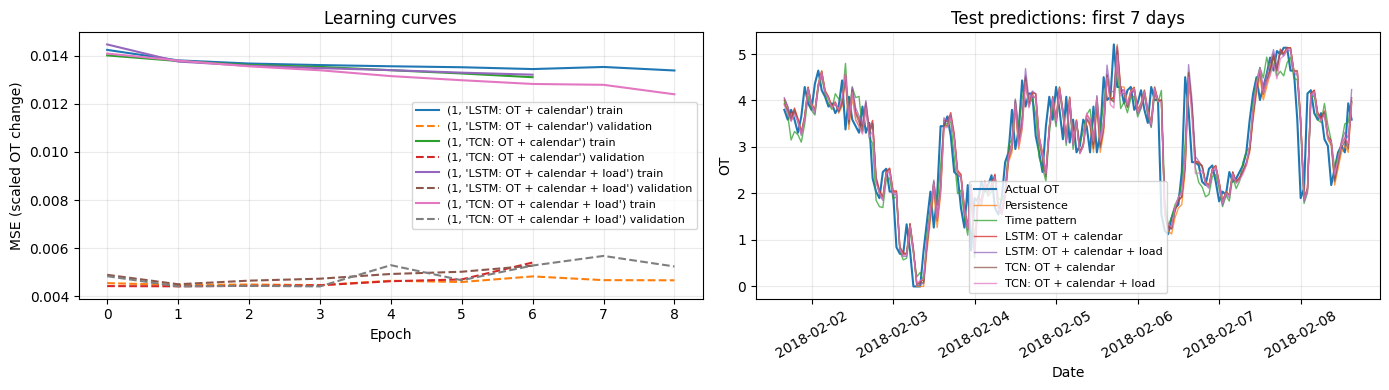

In [146]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for name, history in histories.items():
    axes[0].plot(history["loss"], label=f"{name} train")
    axes[0].plot(history["val_loss"], linestyle="--", label=f"{name} validation")
axes[0].set(title="Learning curves", xlabel="Epoch", ylabel="MSE (scaled OT change)")
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.25)

plot_count = min(len(test_predictions), lookback * 7)
plot_data = test_predictions.iloc[:plot_count]
axes[1].plot(plot_data["date"], plot_data["actual_OT"], label="Actual OT", linewidth=1.5)
for name in predictions_by_split["test"]:
    axes[1].plot(plot_data["date"], plot_data[name], label=name, alpha=0.75, linewidth=1)
axes[1].set(title="Test predictions: first 7 days", xlabel="Date", ylabel="OT")
axes[1].tick_params(axis="x", rotation=30)
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.25)
fig.tight_layout()
plt.show()

## 成果物の保存とエクスポート

評価結果・テスト予測値をCSV、学習曲線・予測図をPNGとして、Google Driveの `assignment-main/model_output/<DATASET>` に保存する。データセットごとにZIPを作成する。同じデータセットで再実行すると、同名の成果物とZIPは上書きされる。

In [147]:
pattern_table_dir = DATA_DIR.parent / "model_output" / DATASET / "tables"
pattern_table_dir.mkdir(parents=True, exist_ok=True)
seasonal_pattern.to_csv(pattern_table_dir / f"{DATASET}_monthly_change_pattern.csv", index=False)
time_pattern.to_csv(pattern_table_dir / f"{DATASET}_time_change_pattern.csv", index=False)
print("季節・時間帯パターンを保存:", pattern_table_dir)

季節・時間帯パターンを保存: /content/drive/Othercomputers/マイ Mac/assignment-main/model_output/ETTh1/tables


In [148]:
import shutil

output_dir = DATA_DIR.parent / "model_output" / DATASET
table_dir = output_dir / "tables"
figure_dir = output_dir / "figures"
for directory in (table_dir, figure_dir):
    directory.mkdir(parents=True, exist_ok=True)

metrics.to_csv(table_dir / f"{DATASET}_metrics.csv", index=False)
test_predictions.to_csv(table_dir / f"{DATASET}_test_predictions.csv", index=False)
fig.savefig(figure_dir / f"{DATASET}_learning_curves_and_predictions.png", dpi=160, bbox_inches="tight")

zip_path = shutil.make_archive(
    str(DATA_DIR.parent / f"{DATASET}_model_outputs"),
    "zip",
    root_dir=output_dir,
)
print("モデル出力フォルダー:", output_dir)
print("ZIP archive:", zip_path)
print("保存したファイル:")
for output_path in sorted(output_dir.rglob("*")):
    if output_path.is_file():
        print("-", output_path.relative_to(DATA_DIR.parent))

モデル出力フォルダー: /content/drive/Othercomputers/マイ Mac/assignment-main/model_output/ETTh1
ZIP archive: /content/drive/Othercomputers/マイ Mac/assignment-main/ETTh1_model_outputs.zip
保存したファイル:
- model_output/ETTh1/figures/ETTh1_learning_curves_and_predictions.png
- model_output/ETTh1/tables/ETTh1_correction_weight_validation.csv
- model_output/ETTh1/tables/ETTh1_hyperparameter_validation.csv
- model_output/ETTh1/tables/ETTh1_lookback_validation.csv
- model_output/ETTh1/tables/ETTh1_metrics.csv
- model_output/ETTh1/tables/ETTh1_monthly_change_pattern.csv
- model_output/ETTh1/tables/ETTh1_test_predictions.csv
- model_output/ETTh1/tables/ETTh1_time_change_pattern.csv
